<a href="https://colab.research.google.com/github/amahendra/IoT-UBM-informatics/blob/main/Smart_City_Traffic_Control_Center_Beginner_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum: Smart City Traffic Control Center
### Connected Vehicles, Virtual IoT Sensors, dan Intelligent Transportation System (ITS)

**Tujuan:** melihat mobil bergerak, berhenti di traffic light, membentuk antrean, dan memantau kemacetan melalui dashboard yang berubah selama simulasi.

**Semua kendaraan dan sensor adalah virtual.** Notebook ini tidak merepresentaiskan V2X, CCTV, dan sistem kendali. Seluruh model lalu lintas disimulasikan.

**Cara menggunakan:** jalankan cell dari atas ke bawah menggunakan **Runtime → Run all** di Google Colab (CPU). Tidak perlu upload CSV atau API key.

Yang akan dipelajari: `for`, `if`, `list`, `dict`, fungsi Python, sensor telemetry, semantic context, traffic alert, dan **OODA (Observe–Orient–Decide–Act)**.

## Cell 1. Import library

Menggunakan Python, Matplotlib, Pandas, dan IPython . `random` membuat pergerakan dan kedatangan mobil sedikit berbeda tetapi bisa direproduksi dengan seed.

In [1]:
import random
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display

print('Library siap. Lanjutkan ke parameter.')

Library siap. Lanjutkan ke parameter.


## Cell 2. Parameter simulasi dan model jalan

Ada **2 lajur menuju timur**, **3 persimpangan**, dan panjang koridor **720 meter**. Setiap detik simulator memperbarui posisi mobil. Mensimulasikan *koordinat lokal*, bukan peta GPS riil.

 `JUMLAH_MOBIL`, `LAMPU_HIJAU`, `SKENARIO`, dan `DELAY_SENSOR` bisa dirubah untuk eksperimen. Jangan mengubah variabel yang lain.

- `normal`: lalu lintas biasa.
- `sibuk`: lebih banyak mobil masuk tiap detik.
- `insiden`: mobil melambat di segmen tengah karena kapasitas jalan berkurang.
- `DELAY_SENSOR`: dashboard melihat data yang tertunda, tetapi mobil tetap bergerak sesuai state simulator.

In [2]:
# ===== PARAMETER YANG BOLEH DIUBAH =====
JUMLAH_MOBIL = 40       # batas jumlah mobil yang boleh masuk simulasi
LAMPU_HIJAU = 20       # lama lampu hijau (detik)
LAMPU_MERAH = 18       # lama lampu merah (detik)
SKENARIO = 'normal'    # 'normal', 'sibuk', atau 'insiden'
DELAY_SENSOR = 2       # keterlambatan pembacaan IoT (detik)
DURASI = 75            # total waktu simulasi (detik)
SEED = 12              # agar hasil percobaan bisa diulang secara random

# ===== DATA JALAN: MATERI SEMANTIC CONTEXT =====
PANJANG_JALAN = 720
LOKASI_LAMPU = [180, 390, 600]
BATAS_KECEPATAN = [45, 40, 50]  # km/jam tiap segmen

# Data ini seperti road_segment registry pada sistem IoT sebenarnya.
ruas_jalan = pd.DataFrame({
    'segment_id': ['S1', 'S2', 'S3'],
    'start_m': [0, 240, 480],
    'end_m': [240, 480, 720],
    'speed_limit_kmh': BATAS_KECEPATAN
})
display(ruas_jalan)

,segment_id,start_m,end_m,speed_limit_kmh
0,S1,0,240,45
1,S2,240,480,40
2,S3,480,720,50


## Cell 3. Traffic light dan aturan gerak

Aturan sederhana yang dipakai:

1. Saat hijau, mobil berusaha bergerak mengikuti batas kecepatan segmennya.
2. Saat merah, mobil berhenti **sebelum** garis lampu.
3. Mobil tidak boleh mendekat kurang dari 12 meter dari mobil di depannya pada lajur yang sama.
4. Dalam skenario `insiden`, segmen S2 dibatasi sementara menjadi 12 km/jam.

Ini **bukan microscopic vehicle dynamics**: tidak ada model akselerasi, pengereman fisik, pergantian lajur, atau konflik lalu lintas yang detail.

In [3]:
def warna_lampu(waktu, nomor_lampu):
    # Offset membuat semua lampu tidak selalu berganti serentak.
    offset = [0, 10, 23][nomor_lampu]
    siklus = LAMPU_HIJAU + LAMPU_MERAH
    fase = (waktu + offset) % siklus
    if fase < LAMPU_HIJAU:
        return 'HIJAU'
    return 'MERAH'


def batas_kecepatan(posisi):
    # Cari segmen jalan dari posisi mobil, lalu ambil batas kecepatannya.
    if posisi < 240:
        return BATAS_KECEPATAN[0]
    if posisi < 480:
        if SKENARIO == 'insiden':
            return 12
        return BATAS_KECEPATAN[1]
    return BATAS_KECEPATAN[2]


for nomor in range(3):
    print('Traffic light', nomor + 1, 'pada t=0:', warna_lampu(0, nomor))

Traffic light 1 pada t=0: HIJAU
Traffic light 2 pada t=0: HIJAU
Traffic light 3 pada t=0: MERAH


## Cell 4. Buat mobil virtual

Setiap mobil disimpan sebagai dictionary sederhana: ID, posisi `x`, nomor lajur, kecepatan, dan status. Posisi diperbarui setiap detik.

Mobil dibuat pada awal simulasi dan sisanya masuk secara bertahap jika pintu masuk lajur cukup kosong.

In [4]:
def buat_mobil(nomor, lajur, posisi):
    return {
        'vehicle_id': 'CAR-' + str(nomor).zfill(3),
        'x': float(posisi),
        'lane': lajur,
        'speed_kmh': 0.0
    }


contoh_mobil = buat_mobil(1, 0, 45)
print('Contoh virtual telemetry:', contoh_mobil)

Contoh virtual telemetry: {'vehicle_id': 'CAR-001', 'x': 45.0, 'lane': 0, 'speed_kmh': 0.0}


## Cell 5. Jalankan simulasi per detik

Ini bagian utama aplikasi. Perhatikan loop `for waktu in range(DURASI + 1)`.

- Mobil terdepan diproses lebih dahulu.
- Kecepatan bergantung pada `speed_limit`, traffic light, dan jarak kendaraan depan.
- Posisi berubah dengan rumus `meter = km/jam ÷ 3.6 × detik`.
- Riwayat setiap detik disimpan untuk membuat animasi dan virtual sensor.

**Catatan:** data dibuat *dalam memori*. CSV input tidak dibutuhkan.

In [5]:
def jalankan_simulasi():
    random.seed(SEED)
    mobil_aktif = []
    riwayat = []
    sudah_dibuat = 0
    mobil_selesai = 0
    pelanggaran_jarak = 0
    pelanggaran_merah = 0

    for waktu in range(DURASI + 1):
        # Mobil baru datang: kemungkinan lebih tinggi saat rush hour.
        peluang_masuk = 0.75 if SKENARIO == 'sibuk' else 0.43
        for lajur in [0, 1]:
            if sudah_dibuat < JUMLAH_MOBIL and random.random() < peluang_masuk:
                dekat_masuk = [m for m in mobil_aktif if m['lane'] == lajur and m['x'] < 18]
                if len(dekat_masuk) == 0:
                    sudah_dibuat += 1
                    mobil_aktif.append(buat_mobil(sudah_dibuat, lajur, 0))

        # Mobil terdepan didahulukan, sehingga posisi mobil depan sudah diperbarui.
        mobil_aktif.sort(key=lambda m: m['x'], reverse=True)
        posisi_depan = {0: PANJANG_JALAN + 100, 1: PANJANG_JALAN + 100}

        for mobil in mobil_aktif:
            x_lama = mobil['x']
            lajur = mobil['lane']
            kecepatan = batas_kecepatan(x_lama)
            x_baru = min(x_lama + kecepatan / 3.6, PANJANG_JALAN)

            # Berhenti tepat sebelum garis lampu merah.
            for i, lokasi in enumerate(LOKASI_LAMPU):
                garis_berhenti = lokasi - 4
                if x_lama <= garis_berhenti and x_baru > garis_berhenti:
                    if warna_lampu(waktu, i) == 'MERAH':
                        x_baru = garis_berhenti

            # Menjaga jarak dari kendaraan di depan.
            x_baru = min(x_baru, posisi_depan[lajur] - 12)
            x_baru = max(x_lama, x_baru)
            mobil['x'] = x_baru
            mobil['speed_kmh'] = round((x_baru - x_lama) * 3.6, 1)
            posisi_depan[lajur] = x_baru

        # Catat state fisik untuk waktu ini.
        foto_keadaan = []
        for mobil in mobil_aktif:
            foto_keadaan.append(mobil.copy())
        riwayat.append(foto_keadaan)

        # Kendaraan yang sudah tiba di tujuan keluar dari jaringan jalan.
        belum_selesai = []
        for mobil in mobil_aktif:
            if mobil['x'] >= PANJANG_JALAN:
                mobil_selesai += 1
            else:
                belum_selesai.append(mobil)
        mobil_aktif = belum_selesai

        # Pemeriksaan jarak antar mobil pada lajur yang sama.
        for lajur in [0, 1]:
            posisi = sorted([m['x'] for m in mobil_aktif if m['lane'] == lajur])
            for j in range(1, len(posisi)):
                if posisi[j] - posisi[j-1] < 11.99:
                    pelanggaran_jarak += 1

    print('Mobil masuk:', sudah_dibuat, '| Mobil selesai:', mobil_selesai)
    return riwayat, {'mobil_masuk': sudah_dibuat,
                     'mobil_selesai': mobil_selesai,
                     'pelanggaran_jarak': pelanggaran_jarak,
                     'pelanggaran_merah': pelanggaran_merah}


riwayat, statistik_simulasi = jalankan_simulasi()
print('Jumlah frame:', len(riwayat))
print('Pemeriksaan jarak minimum:', statistik_simulasi['pelanggaran_jarak'], 'pelanggaran')

Mobil masuk: 40 | Mobil selesai: 2
Jumlah frame: 76
Pemeriksaan jarak minimum: 0 pelanggaran


## Cell 6. Virtual IoT Sensors dan semantic context

Perhatikan perbedaan penting:

- **Ground truth:** posisi semua mobil dalam simulator.
- **Observed data:** salinan data dari beberapa detik sebelumnya (`DELAY_SENSOR`). Inilah yang dianggap diterima ITS dari virtual sensors.
- **Semantic context:** pengukuran kecepatan harus dihubungkan dengan `segment_id` dan `speed_limit_kmh` sebelum disebut overspeed.

Tidak ada MQTT, V2X, maupun telemetry fisik yang dikirim melalui jaringan dalam notebook ini.

In [6]:
def nama_segmen(posisi):
    if posisi < 240:
        return 'S1'
    if posisi < 480:
        return 'S2'
    return 'S3'


def baca_sensor(waktu):
    waktu_sensor = max(0, waktu - DELAY_SENSOR)
    data_sensor = []
    for mobil in riwayat[waktu_sensor]:
        data_sensor.append({
            'timestamp': waktu_sensor,
            'vehicle_id': mobil['vehicle_id'],
            'segment_id': nama_segmen(mobil['x']),
            'x': mobil['x'],
            'lane': mobil['lane'],
            'speed_kmh': mobil['speed_kmh']
        })
    return pd.DataFrame(data_sensor)


telemetry = baca_sensor(30)
if len(telemetry) > 0:
    telemetry = telemetry.merge(ruas_jalan[['segment_id', 'speed_limit_kmh']], on='segment_id')
    telemetry['overspeed'] = telemetry['speed_kmh'] > telemetry['speed_limit_kmh']
display(telemetry.head())

,timestamp,vehicle_id,segment_id,x,lane,speed_kmh,speed_limit_kmh,overspeed
0,28,CAR-001,S2,338.888889,1,40.0,40,False
1,28,CAR-002,S2,327.777778,0,40.0,40,False
2,28,CAR-003,S1,176.000000,0,0.0,45,False
3,28,CAR-006,S1,176.000000,1,0.0,45,False
4,28,CAR-004,S1,164.000000,0,0.0,45,False


## Cell 7. Hitung kondisi lalu lintas dan OODA

**Observe:** jumlah mobil dan kecepatan dari observed telemetry.

**Orient:** hubungkan posisi dengan segment jalan dan speed limit.

**Decide:** gunakan aturan contoh: antrean panjang bila minimal 5 mobil hampir berhenti; *congestion alert* bila rata-rata kecepatan kurang dari 12 km/jam dan ada minimal 4 mobil.

**Act:** saran bagi operator, bukan pengendalian traffic light maupun mobil secara otomatis.

Threshold adalah contoh latihan, bukan indikator keselamatan yang tervalidasi.

In [7]:
def analisis_lalu_lintas(waktu):
    data = baca_sensor(waktu)
    hasil = []
    jumlah_berhenti = 0

    for segmen in ['S1', 'S2', 'S3']:
        if len(data) == 0:
            bagian = pd.DataFrame()
        else:
            bagian = data[data['segment_id'] == segmen]
        jumlah = len(bagian)
        rata_kecepatan = round(bagian['speed_kmh'].mean(), 1) if jumlah else 0.0
        antre = int((bagian['speed_kmh'] < 3).sum()) if jumlah else 0
        jumlah_berhenti += antre

        if antre >= 5 or (jumlah >= 4 and rata_kecepatan < 12):
            status = 'MACET'
        elif jumlah >= 3 and rata_kecepatan < 25:
            status = 'PADAT'
        else:
            status = 'LANCAR'

        hasil.append({'segment_id': segmen, 'vehicles': jumlah,
                      'avg_speed': rata_kecepatan, 'queue': antre, 'status': status})

    tabel = pd.DataFrame(hasil)
    jumlah_alert = int((tabel['status'] == 'MACET').sum())
    if jumlah_alert > 0:
        saran = 'Periksa ruas macet; evaluasi timing lampu dan pengalihan arus.'
    elif (tabel['status'] == 'PADAT').any():
        saran = 'Pantau ruas padat dan panjang antrean.'
    else:
        saran = 'Lalu lintas terpantau normal.'
    return tabel, jumlah_alert, saran


tabel_status, total_alert, rekomendasi = analisis_lalu_lintas(40)
display(tabel_status)
print('OODA / Act:', rekomendasi)

,segment_id,vehicles,avg_speed,queue,status
0,S1,24,45.0,0,LANCAR
1,S2,2,40.0,0,LANCAR
2,S3,0,0.0,0,LANCAR


OODA / Act: Lalu lintas terpantau normal.


## Cell 8. Dashboard ITS yang bergerak

**Simulasi utama:** jalankan cell, kemudian klik tombol **Play** pada animasi.

Dashboard menampilkan:
- Mobil bergerak (biru); mobil yang hampir berhenti berwarna merah.
- Lampu lalu lintas hijau/merah berubah sesuai waktu simulator.
- Traffic KPI dan kondisi tiap segmen dihitung dari **virtual IoT observations**.
- Rekomendasi operator berdasarkan OODA.

Animasi dibangkitkan dari hasil simulasi; tidak membutuhkan server dan tidak ada live network connection. Untuk menjaga kinerja Colab, hanya setiap 2 detik yang ditampilkan.

In [8]:
# Buat animasi: pada frame yang berbeda, posisi mobil dan dashboard berubah.
def gambar_frame(waktu, ax_jalan, ax_status, ax_info):
    ax_jalan.clear()
    ax_status.clear()
    ax_info.clear()

    # Peta skematis dua lajur (meter), bukan peta geografi sebenarnya.
    ax_jalan.set_xlim(-20, PANJANG_JALAN + 20)
    ax_jalan.set_ylim(-0.65, 1.65)
    ax_jalan.set_facecolor('#eef4f8')
    ax_jalan.axhspan(-0.35, 1.35, color='#cbd5e1')
    ax_jalan.axhline(0.5, color='white', linestyle='--', linewidth=2)

    for i, lokasi in enumerate(LOKASI_LAMPU):
        warna = 'green' if warna_lampu(waktu, i) == 'HIJAU' else 'red'
        ax_jalan.axvline(lokasi, color=warna, linestyle=':', linewidth=2)
        ax_jalan.scatter(lokasi, 1.45, color=warna, s=100, edgecolors='black', zorder=5)

    for mobil in riwayat[waktu]:
        warna = '#ef4444' if mobil['speed_kmh'] < 3 else '#2563eb'
        ax_jalan.plot(mobil['x'], mobil['lane'], 's', markersize=9,
                      markerfacecolor=warna, markeredgecolor='white')
    ax_jalan.set_yticks([0, 1], ['Lane 1', 'Lane 2'])
    ax_jalan.set_xlabel('Posisi sepanjang koridor (meter)')
    ax_jalan.set_title('Mobil bergerak dan traffic light | t=' + str(waktu) + ' detik')

    tabel, alerts, saran = analisis_lalu_lintas(waktu)
    colors = {'LANCAR':'#16a34a', 'PADAT':'#eab308', 'MACET':'#ef4444'}
    ax_status.bar(tabel['segment_id'], tabel['vehicles'],
                  color=[colors[s] for s in tabel['status']])
    ax_status.set_ylim(0, max(8, tabel['vehicles'].max() + 2))
    ax_status.set_ylabel('Observed vehicles')
    ax_status.set_title('Status ruas dari sensor')
    for j, bar in enumerate(ax_status.patches):
        ax_status.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.2,
                       tabel.iloc[j]['status'], ha='center', fontsize=9)

    semua_data = baca_sensor(waktu)
    speed = round(semua_data['speed_kmh'].mean(), 1) if len(semua_data) else 0
    ax_info.axis('off')
    teks = ('OBSERVED @ t=' + str(max(0, waktu-DELAY_SENSOR)) + ' s' +
            '\nVehicles: ' + str(len(semua_data)) +
            '\nAverage speed: ' + str(speed) + ' km/h' +
            '\nCongestion alerts: ' + str(alerts) +
            '\n\nOODA recommendation:\n' + saran)
    ax_info.text(0.03, 0.95, teks, va='top', fontsize=11, linespacing=1.55)


fig, (ax_jalan, ax_status, ax_info) = plt.subplots(
    3, 1, figsize=(12, 9), gridspec_kw={'height_ratios': [2.2, 1.6, 1.3]})
plt.tight_layout(pad=3)

def update(frame):
    gambar_frame(frame, ax_jalan, ax_status, ax_info)

# interval=160 ms adalah kecepatan playback; satu frame = 2 detik waktu simulasi.
frames = list(range(0, DURASI + 1, 2))
film = animation.FuncAnimation(fig, update, frames=frames, interval=160, repeat=True)
plt.close(fig)
display(HTML(film.to_jshtml()))

## Cell 9. Grafik traffic history

Animasi menunjukkan apa yang terjadi, sedangkan grafik membantu melihat **tren**. Data di bawah dihitung untuk setiap waktu berdasarkan sensor virtual yang dapat terlambat.

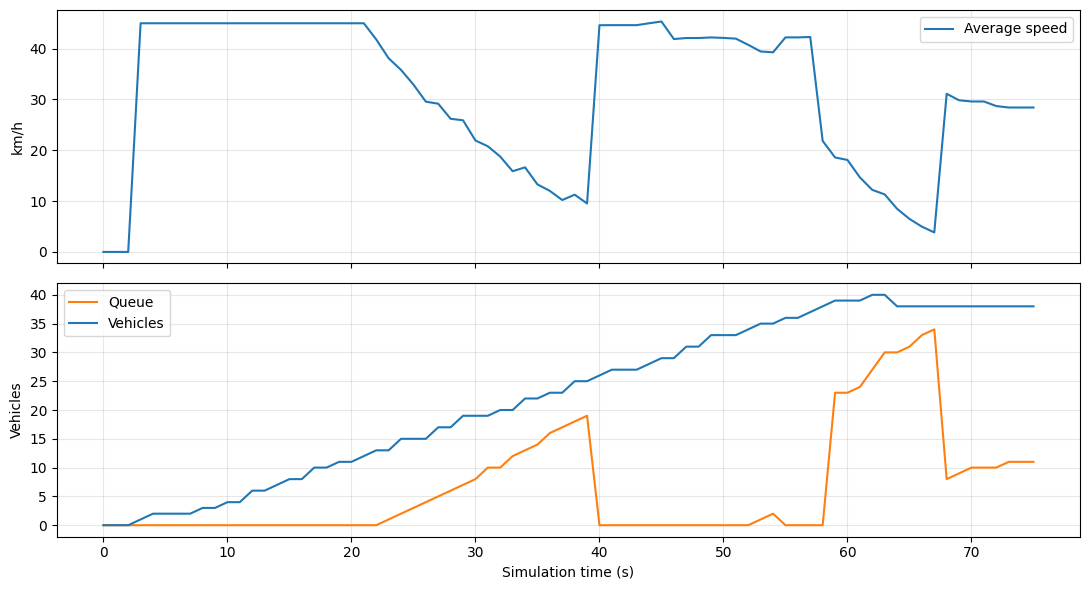

,time_s,vehicles,avg_speed_kmh,queue_count,congestion_alerts
71,71,38,29.605263,10,1
72,72,38,28.705263,10,1
73,73,38,28.421053,11,1
74,74,38,28.421053,11,1
75,75,38,28.421053,11,1


In [12]:
rekap = []
for waktu in range(DURASI + 1):
    data = baca_sensor(waktu)
    tabel, alert, saran = analisis_lalu_lintas(waktu)
    rekap.append({
        'time_s': waktu,
        'vehicles': len(data),
        'avg_speed_kmh': data['speed_kmh'].mean() if len(data) else 0,
        'queue_count': int((data['speed_kmh'] < 3).sum()) if len(data) else 0,
        'congestion_alerts': alert
    })

riwayat_kpi = pd.DataFrame(rekap)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(riwayat_kpi['time_s'], riwayat_kpi['avg_speed_kmh'], label='Average speed')
axes[0].set_ylabel('km/h'); axes[0].grid(alpha=.3); axes[0].legend()
axes[1].plot(riwayat_kpi['time_s'], riwayat_kpi['queue_count'], label='Queue', color='tab:orange')
axes[1].plot(riwayat_kpi['time_s'], riwayat_kpi['vehicles'], label='Vehicles', color='tab:blue')
axes[1].set_ylabel('Vehicles'); axes[1].set_xlabel('Simulation time (s)')
axes[1].grid(alpha=.3); axes[1].legend()
plt.tight_layout(); plt.show()
display(riwayat_kpi.tail())

## Cell 10. Eksperimen sederhana

Coba ubah **Cell 2**, lalu jalankan lagi Cell 3 sampai Cell 10.

1. Ubah `JUMLAH_MOBIL` menjadi 20, kemudian 80. Bandingkan antrean.
2. Ubah `LAMPU_HIJAU` menjadi 10, kemudian 35. Apakah antrean berubah?
3. Bandingkan `SKENARIO='normal'`, `'sibuk'`, dan `'insiden'`.
4. Ubah `DELAY_SENSOR` dari 0 ke 8 detik. Perhatikan perbedaan *ground truth* dan informasi dashboard.
5. Ubah salah satu `BATAS_KECEPATAN`. Amati perbedaan kecepatan dan antrean.

**Catat satu hal penting:** ini simulasi edukasional sederhana, sehingga efek perubahan parameter tidak dapat dianggap sebagai kesimpulan tentang rekayasa lalu lintas nyata.

In [10]:
# Ringkasan sederhana hasil percobaan terakhir.
print('Skenario:', SKENARIO)
print('Batas jumlah mobil:', JUMLAH_MOBIL)
print('Lampu hijau:', LAMPU_HIJAU, 'detik')
print('Delay sensor:', DELAY_SENSOR, 'detik')
print('Mobil selesai:', statistik_simulasi['mobil_selesai'])
print('Puncak antrean:', riwayat_kpi['queue_count'].max())
print('Rata-rata kecepatan dari sensor:', round(riwayat_kpi['avg_speed_kmh'].mean(), 1), 'km/jam')
print('Jumlah waktu dengan congestion alert:', int((riwayat_kpi['congestion_alerts'] > 0).sum()))

Skenario: normal
Batas jumlah mobil: 40
Lampu hijau: 20 detik
Delay sensor: 2 detik
Mobil selesai: 2
Puncak antrean: 34
Rata-rata kecepatan dari sensor: 31.4 km/jam
Jumlah waktu dengan congestion alert: 31


## Cell 11. Validasi teknis

Kita perlu memastikan simulasi tidak hanya terlihat menarik, tetapi juga masuk akal. Pemeriksaan berikut memastikan jumlah frame benar, posisi dalam koridor, jarak minimum tidak dilanggar, dan sensor membaca state dari waktu yang tepat.

In [11]:
assert len(riwayat) == DURASI + 1, 'Jumlah simulation frames salah.'
assert statistik_simulasi['pelanggaran_jarak'] == 0, 'Jarak antar mobil terlalu dekat.'
for keadaan in riwayat:
    for mobil in keadaan:
        assert 0 <= mobil['x'] <= PANJANG_JALAN, 'Posisi di luar jalan.'
        assert mobil['speed_kmh'] >= 0, 'Kecepatan negatif.'

waktu_uji = min(20, DURASI)
data_uji = baca_sensor(waktu_uji)
if len(data_uji):
    assert (data_uji['timestamp'] == max(0, waktu_uji-DELAY_SENSOR)).all()

print('VALIDASI LULUS: frames, posisi, jarak aman, kecepatan, dan sensor delay.')

VALIDASI LULUS: frames, posisi, jarak aman, kecepatan, dan sensor delay.


## Kesimpulan

- **Simulator** menghasilkan kondisi kendaraan dan traffic light yang berubah setiap detik.
- **Virtual IoT sensors** membaca snapshot keadaan, dengan opsi delay, bukan mengendalikan mobil.
- **Semantic context** mengaitkan posisi kendaraan dengan segmen jalan dan batas kecepatan.
- **ITS analytics** menghitung kondisi ruas, antrean, dan alert menggunakan aturan sederhana.
- **OODA** menghasilkan rekomendasi untuk operator; tidak melakukan automatic actuation.

**Keterbatasan:** model ini tidak memiliki lane change, acceleration physics, traffic flow calibration, data GPS nyata, V2X, atau sensor eksternal. Gunakan SUMO atau UXsim untuk studi rekayasa lalu lintas tingkat lanjut.